In [1]:

import pandas as pd
from pathlib import Path

# Locate the dataset
file_path = Path("../data/raw/1.csv")

# Load the dataset
df = pd.read_csv(file_path)

# Display basic information
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!
Number of rows and columns: (1063, 1)

Column names:
['datetime;Accelerometer1RMS;Accelerometer2RMS;Current;Pressure;Temperature;Thermocouple;Voltage;Volume Flow RateRMS;anomaly;changepoint']

First 5 rows:
  datetime;Accelerometer1RMS;Accelerometer2RMS;Current;Pressure;Temperature;Thermocouple;Voltage;Volume Flow RateRMS;anomaly;changepoint
0  2020-03-09 16:16:30;0.0275454;0.0411269;0.6735...                                                                                    
1  2020-03-09 16:16:31;0.027996899999999998;0.039...                                                                                    
2  2020-03-09 16:16:32;0.028418400000000003;0.038...                                                                                    
3  2020-03-09 16:16:33;0.0276254;0.0393665;0.5662...                                                                                    
4  2020-03-09 16:16:34;0.0274841;0.0418539;1.2921...                           

In [2]:

import pandas as pd
from pathlib import Path

# Correctly load the semicolon-separated dataset
file_path = Path("../data/raw/1.csv")
df = pd.read_csv(file_path, sep=";")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!
Rows and columns: (1063, 11)

Column names:
['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

First 5 rows:
              datetime  Accelerometer1RMS  Accelerometer2RMS   Current  \
0  2020-03-09 16:16:30           0.027545           0.041127  0.673506   
1  2020-03-09 16:16:31           0.027997           0.039100  0.772264   
2  2020-03-09 16:16:32           0.028418           0.038872  0.675520   
3  2020-03-09 16:16:33           0.027625           0.039366  0.566279   
4  2020-03-09 16:16:34           0.027484           0.041854  1.292170   

   Pressure  Temperature  Thermocouple  Voltage  Volume Flow RateRMS  anomaly  \
0  0.054711      67.8345       24.3164  240.513                 32.0      0.0   
1  0.054711      67.8704       24.3279  229.523                 32.0      0.0   
2  0.054711      67.7882       24.3261  242.708        

In [3]:

# Convert datetime text to datetime objects
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

# Check data types
print("Updated data types:")
print(df.dtypes)

# Check invalid datetime values
print("\nInvalid datetime values:")
print(df["datetime"].isna().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Check dataset size
print("\nDataset shape:")
print(df.shape)


Updated data types:
datetime               datetime64[us]
Accelerometer1RMS             float64
Accelerometer2RMS             float64
Current                       float64
Pressure                      float64
Temperature                   float64
Thermocouple                  float64
Voltage                       float64
Volume Flow RateRMS           float64
anomaly                       float64
changepoint                   float64
dtype: object

Invalid datetime values:
0

Duplicate rows:
0

Dataset shape:
(1063, 11)


In [4]:

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Statistical summary
print(numeric_df.describe().T)

# Check for infinite values
import numpy as np

print("\nInfinite values per column:")
print(np.isinf(numeric_df).sum())


                      count        mean        std        min         25%  \
Accelerometer1RMS    1063.0    0.027663   0.000333   0.026455    0.027434   
Accelerometer2RMS    1063.0    0.040037   0.001086   0.036972    0.039276   
Current              1063.0    1.195240   7.113407   0.394058    0.753505   
Pressure             1063.0    0.048541   0.270689  -0.929070    0.054711   
Temperature          1063.0   67.895174   0.695198  66.201900   67.412450   
Thermocouple         1063.0   24.265096   0.021573  24.217000   24.252950   
Voltage              1063.0  229.924824  13.259556   0.580776  223.570000   
Volume Flow RateRMS  1063.0   31.472275   1.314535  28.040000   31.039050   
anomaly              1063.0    0.313264   0.464039   0.000000    0.000000   
changepoint          1063.0    0.003763   0.061256   0.000000    0.000000   

                            50%         75%         max  
Accelerometer1RMS      0.027674    0.027892    0.028554  
Accelerometer2RMS      0.040098    0

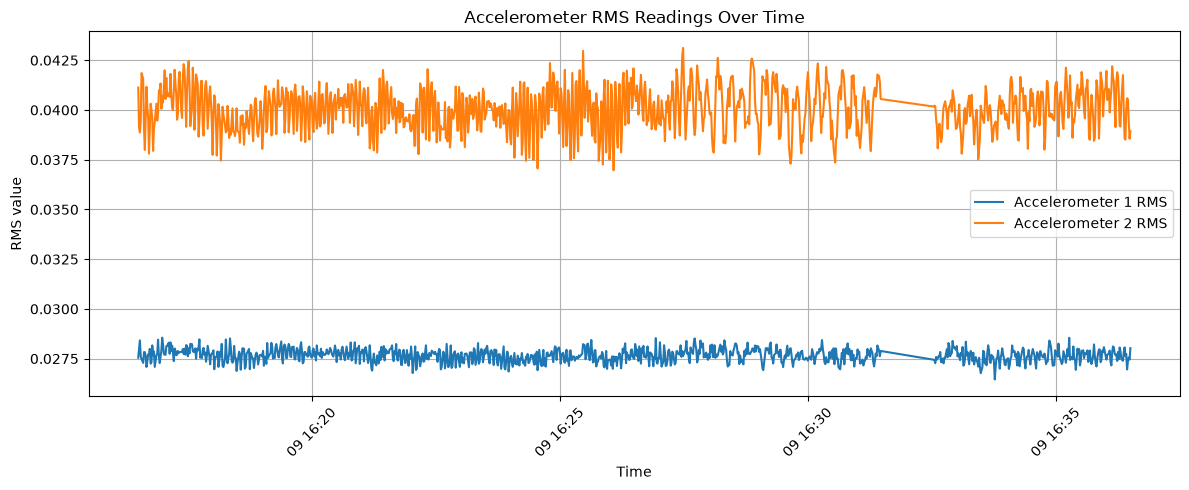

In [5]:

import matplotlib.pyplot as plt

# Plot accelerometer RMS values over time
plt.figure(figsize=(12, 5))

plt.plot(
    df["datetime"],
    df["Accelerometer1RMS"],
    label="Accelerometer 1 RMS"
)

plt.plot(
    df["datetime"],
    df["Accelerometer2RMS"],
    label="Accelerometer 2 RMS"
)

plt.xlabel("Time")
plt.ylabel("RMS value")
plt.title("Accelerometer RMS Readings Over Time")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [6]:

print("Anomaly label counts:")
print(df["anomaly"].value_counts())

print("\nChange-point label counts:")
print(df["changepoint"].value_counts())

print("\nRows with unusually high current:")
print(
    df.loc[
        df["Current"] > 10,
        ["datetime", "Current", "Voltage", "anomaly", "changepoint"]
    ]
)


Anomaly label counts:
anomaly
0.0    730
1.0    333
Name: count, dtype: int64

Change-point label counts:
changepoint
0.0    1059
1.0       4
Name: count, dtype: int64

Rows with unusually high current:
                datetime  Current   Voltage  anomaly  changepoint
1002 2020-03-09 16:35:27  232.734  0.580776      0.0          0.0


In [7]:
print("First 10 anomaly rows:")
print(df[df["anomaly"] == 1].head(10))

print("\nRows around the unusual current reading:")
print(
    df.loc[998:1005, [
        "datetime",
        "Current",
        "Voltage",
        "Accelerometer1RMS",
        "Accelerometer2RMS",
        "anomaly",
        "changepoint"
    ]]
)

First 10 anomaly rows:
               datetime  Accelerometer1RMS  Accelerometer2RMS   Current  \
560 2020-03-09 16:26:30           0.027489           0.040797  1.162620   
561 2020-03-09 16:26:31           0.028236           0.040921  0.478813   
562 2020-03-09 16:26:32           0.028028           0.040447  1.212860   
563 2020-03-09 16:26:33           0.027633           0.041229  0.953656   
564 2020-03-09 16:26:34           0.027954           0.040867  1.139300   
565 2020-03-09 16:26:35           0.027384           0.039770  0.449261   
566 2020-03-09 16:26:36           0.028119           0.040324  0.876434   
567 2020-03-09 16:26:38           0.027249           0.041766  0.784459   
568 2020-03-09 16:26:39           0.028023           0.040882  0.450071   
569 2020-03-09 16:26:40           0.027779           0.039835  0.857629   

     Pressure  Temperature  Thermocouple  Voltage  Volume Flow RateRMS  \
560 -0.273216      67.4538       24.2726  231.836              32.0000   
561

In [8]:
# Compare sensor readings for normal and anomaly-labelled rows
sensor_columns = [
    "Accelerometer1RMS",
    "Accelerometer2RMS",
    "Current",
    "Pressure",
    "Temperature",
    "Voltage",
    "Volume Flow RateRMS"
]

comparison = df.groupby("anomaly")[sensor_columns].mean().round(4)

print("Average sensor readings by anomaly label:")
print(comparison)

Average sensor readings by anomaly label:
         Accelerometer1RMS  Accelerometer2RMS  Current  Pressure  Temperature  \
anomaly                                                                         
0.0                 0.0276             0.0400   1.3048    0.0556      67.7797   
1.0                 0.0277             0.0401   0.9551    0.0330      68.1484   

          Voltage  Volume Flow RateRMS  
anomaly                                 
0.0      229.9408              32.1754  
1.0      229.8897              29.9309  


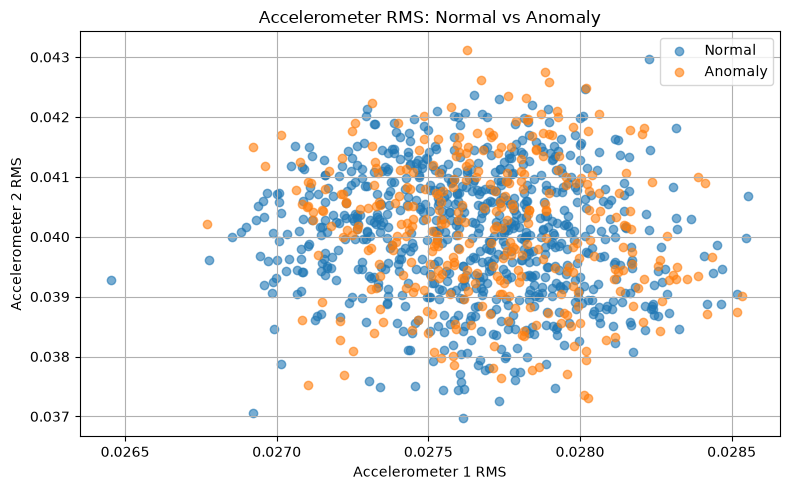

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for label, name in [(0, "Normal"), (1, "Anomaly")]:
    subset = df[df["anomaly"] == label]

    plt.scatter(
        subset["Accelerometer1RMS"],
        subset["Accelerometer2RMS"],
        label=name,
        alpha=0.6
    )

plt.xlabel("Accelerometer 1 RMS")
plt.ylabel("Accelerometer 2 RMS")
plt.title("Accelerometer RMS: Normal vs Anomaly")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
# Check time intervals between consecutive readings
time_diff = df["datetime"].diff().dt.total_seconds()

print("Time interval counts (seconds):")
print(time_diff.value_counts().sort_index())

print("\nAvailable columns:")
print(df.columns.tolist())

print("\nFirst 10 accelerometer readings:")
print(
    df[[
        "datetime",
        "Accelerometer1RMS",
        "Accelerometer2RMS"
    ]].head(10)
)

Time interval counts (seconds):
datetime
1.0     986
2.0      75
64.0      1
Name: count, dtype: int64

Available columns:
['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

First 10 accelerometer readings:
             datetime  Accelerometer1RMS  Accelerometer2RMS
0 2020-03-09 16:16:30           0.027545           0.041127
1 2020-03-09 16:16:31           0.027997           0.039100
2 2020-03-09 16:16:32           0.028418           0.038872
3 2020-03-09 16:16:33           0.027625           0.039366
4 2020-03-09 16:16:34           0.027484           0.041854
5 2020-03-09 16:16:36           0.027288           0.041571
6 2020-03-09 16:16:37           0.027832           0.039037
7 2020-03-09 16:16:38           0.027826           0.037990
8 2020-03-09 16:16:39           0.027646           0.039669
9 2020-03-09 16:16:40           0.027084           0.041167


In [11]:
# Find time gaps greater than 2 seconds
time_diff = df["datetime"].diff().dt.total_seconds()

gap_rows = df.loc[
    time_diff > 2,
    ["datetime", "Accelerometer1RMS", "Accelerometer2RMS"]
].copy()

gap_rows["time_gap_seconds"] = time_diff[time_diff > 2]

print("Rows with time gaps greater than 2 seconds:")
print(gap_rows)

Rows with time gaps greater than 2 seconds:
               datetime  Accelerometer1RMS  Accelerometer2RMS  \
838 2020-03-09 16:32:32           0.027447           0.040173   

     time_gap_seconds  
838              64.0  


In [12]:
from pathlib import Path

# Create the output folder if needed
clean_folder = Path("../data/clean")
clean_folder.mkdir(parents=True, exist_ok=True)

# Save a separate copy of the current dataset
output_file = clean_folder / "sensor_data_clean.csv"
df.to_csv(output_file, index=False)

print("Dataset saved successfully!")
print("File location:", output_file.resolve())
print("Rows and columns:", df.shape)

Dataset saved successfully!
File location: C:\Users\Sowmya\OneDrive\Desktop\soumya\Sensor-Telemetry-Anomaly-detection-\data\clean\sensor_data_clean.csv
Rows and columns: (1063, 11)


In [ ]:
import pandas as pd
from pathlib import Path

clean_file = Path("../data/clean/sensor_data_clean.csv")

clean_df = pd.read_csv(clean_file)

print("Saved dataset loaded successfully!")
print("Shape:", clean_df.shape)
print("\nMissing values:")
print(clean_df.isnull().sum())
print("\nFirst 5 rows:")
print(clean_df.head())

Saved dataset loaded successfully!
Shape: (1063, 11)

Missing values:
datetime               0
Accelerometer1RMS      0
Accelerometer2RMS      0
Current                0
Pressure               0
Temperature            0
Thermocouple           0
Voltage                0
Volume Flow RateRMS    0
anomaly                0
changepoint            0
dtype: int64

First 5 rows:
              datetime  Accelerometer1RMS  Accelerometer2RMS   Current  \
0  2020-03-09 16:16:30           0.027545           0.041127  0.673506   
1  2020-03-09 16:16:31           0.027997           0.039100  0.772264   
2  2020-03-09 16:16:32           0.028418           0.038872  0.675520   
3  2020-03-09 16:16:33           0.027625           0.039366  0.566279   
4  2020-03-09 16:16:34           0.027484           0.041854  1.292170   

   Pressure  Temperature  Thermocouple  Voltage  Volume Flow RateRMS  anomaly  \
0  0.054711      67.8345       24.3164  240.513                 32.0      0.0   
1  0.054711      67.

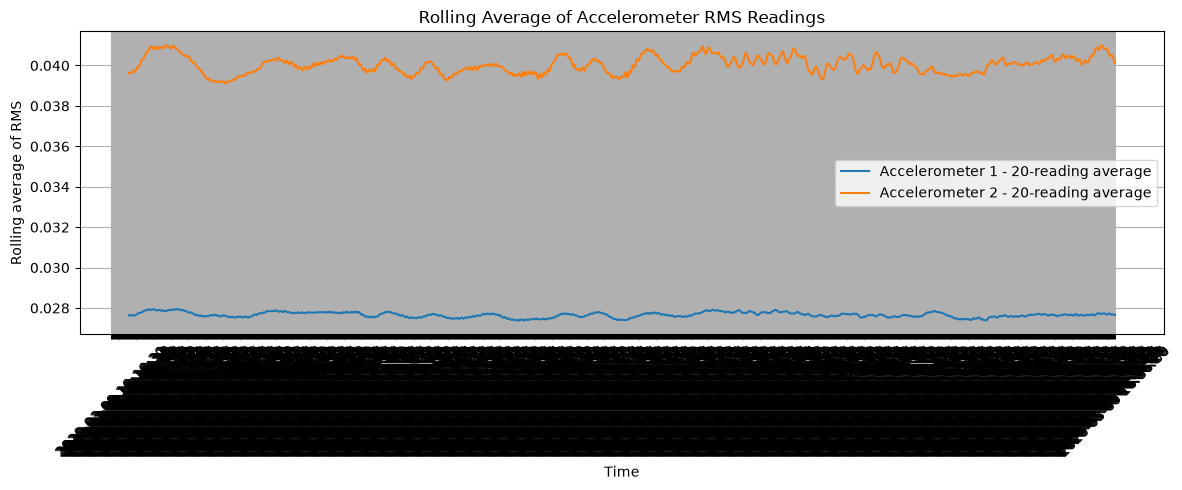

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    clean_df["datetime"],
    clean_df["Accelerometer1RMS"].rolling(window=20).mean(),
    label="Accelerometer 1 - 20-reading average"
)

plt.plot(
    clean_df["datetime"],
    clean_df["Accelerometer2RMS"].rolling(window=20).mean(),
    label="Accelerometer 2 - 20-reading average"
)

plt.xlabel("Time")
plt.ylabel("Rolling average of RMS")
plt.title("Rolling Average of Accelerometer RMS Readings")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    clean_df["datetime"],
    clean_df["Accelerometer1RMS"].rolling(20).mean(),
    label="Accelerometer 1"
)

ax.plot(
    clean_df["datetime"],
    clean_df["Accelerometer2RMS"].rolling(20).mean(),
    label="Accelerometer 2"
)

ax.set_xlabel("Time")
ax.set_ylabel("20-reading rolling average")
ax.set_title("Rolling Average of Accelerometer RMS Readings")

# Display only 6 time labels
positions = np.linspace(0, len(clean_df) - 1, 6, dtype=int)
ax.set_xticks(clean_df["datetime"].iloc[positions])
ax.tick_params(axis="x", rotation=30)

ax.legend()
ax.grid(True)
fig.tight_layout()
plt.show()

In [1]:

import pandas as pd

# Load the raw sensor dataset
df = pd.read_csv("../data/raw/1.csv", sep=";")

# Display dataset information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)


Dataset shape: (1063, 11)

Column names:
['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

First 5 rows:


,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint
0,2020-03-09 16:16:30,0.027545,0.041127,0.673506,0.054711,67.8345,24.3164,240.513,32.0,0.0,0.0
1,2020-03-09 16:16:31,0.027997,0.039100,0.772264,0.054711,67.8704,24.3279,229.523,32.0,0.0,0.0
2,2020-03-09 16:16:32,0.028418,0.038872,0.675520,0.054711,67.7882,24.3261,242.708,32.0,0.0,0.0
3,2020-03-09 16:16:33,0.027625,0.039366,0.566279,-0.273216,67.7918,24.3323,229.709,32.0,0.0,0.0
4,2020-03-09 16:16:34,0.027484,0.041854,1.292170,0.054711,67.7368,24.3250,242.746,32.0,0.0,0.0



Data types:
datetime                   str
Accelerometer1RMS      float64
Accelerometer2RMS      float64
Current                float64
Pressure               float64
Temperature            float64
Thermocouple           float64
Voltage                float64
Volume Flow RateRMS    float64
anomaly                float64
changepoint            float64
dtype: object


In [2]:

# Summary of accelerometer readings
print("Accelerometer 1 summary:")
display(df["Accelerometer1RMS"].describe())

print("\nAccelerometer 2 summary:")
display(df["Accelerometer2RMS"].describe())

# Check how many anomaly records exist
print("\nAnomaly counts:")
display(df["anomaly"].value_counts())

Accelerometer 1 summary:


count    1063.000000
mean        0.027663
std         0.000333
min         0.026455
25%         0.027434
50%         0.027674
75%         0.027892
max         0.028554
Name: Accelerometer1RMS, dtype: float64


Accelerometer 2 summary:


count    1063.000000
mean        0.040037
std         0.001086
min         0.036972
25%         0.039276
50%         0.040098
75%         0.040828
max         0.043122
Name: Accelerometer2RMS, dtype: float64


Anomaly counts:


anomaly
0.0    730
1.0    333
Name: count, dtype: int64

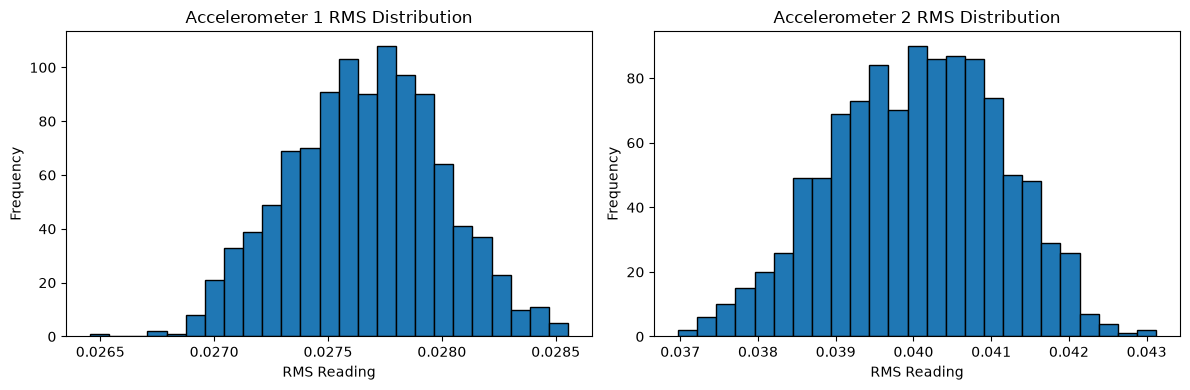

In [3]:

import matplotlib.pyplot as plt

# Create two histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["Accelerometer1RMS"], bins=25, edgecolor="black")
axes[0].set_title("Accelerometer 1 RMS Distribution")
axes[0].set_xlabel("RMS Reading")
axes[0].set_ylabel("Frequency")

axes[1].hist(df["Accelerometer2RMS"], bins=25, edgecolor="black")
axes[1].set_title("Accelerometer 2 RMS Distribution")
axes[1].set_xlabel("RMS Reading")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


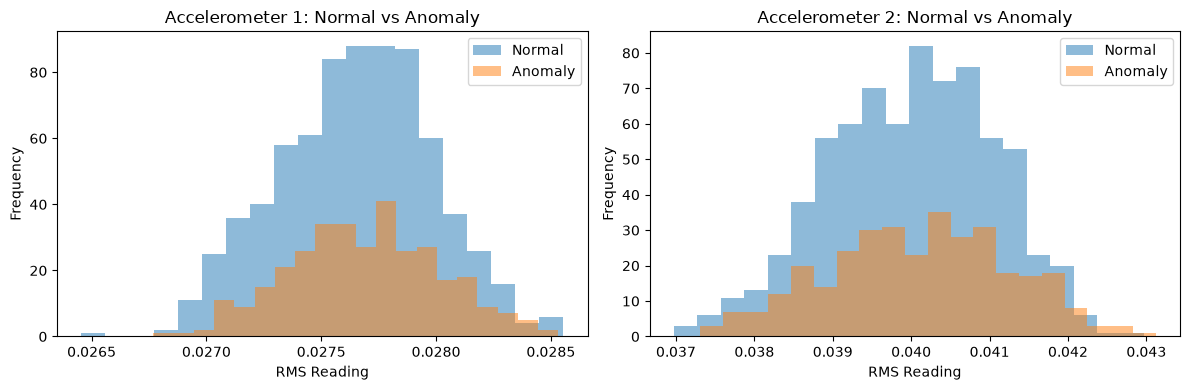

In [4]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for label, group in df.groupby("anomaly"):
    name = "Anomaly" if label == 1 else "Normal"

    axes[0].hist(
        group["Accelerometer1RMS"],
        bins=20,
        alpha=0.5,
        label=name
    )

    axes[1].hist(
        group["Accelerometer2RMS"],
        bins=20,
        alpha=0.5,
        label=name
    )

axes[0].set_title("Accelerometer 1: Normal vs Anomaly")
axes[0].set_xlabel("RMS Reading")
axes[0].set_ylabel("Frequency")
axes[0].legend()

axes[1].set_title("Accelerometer 2: Normal vs Anomaly")
axes[1].set_xlabel("RMS Reading")
axes[1].set_ylabel("Frequency")
axes[1].legend()

plt.tight_layout()
plt.show()


In [5]:

# Compare sensor readings by anomaly label
comparison = df.groupby("anomaly")[
    ["Accelerometer1RMS", "Accelerometer2RMS"]
].agg(["mean", "min", "max"])

print("RMS comparison: Normal vs Anomaly")
display(comparison)


RMS comparison: Normal vs Anomaly


Accelerometer1RMS                     Accelerometer2RMS            \
                     mean       min       max              mean       min   
anomaly                                                                     
0.0              0.027650  0.026455  0.028554          0.040007  0.036972   
1.0              0.027692  0.026769  0.028533          0.040102  0.037304   

                   
              max  
anomaly            
0.0      0.042974  
1.0      0.043122

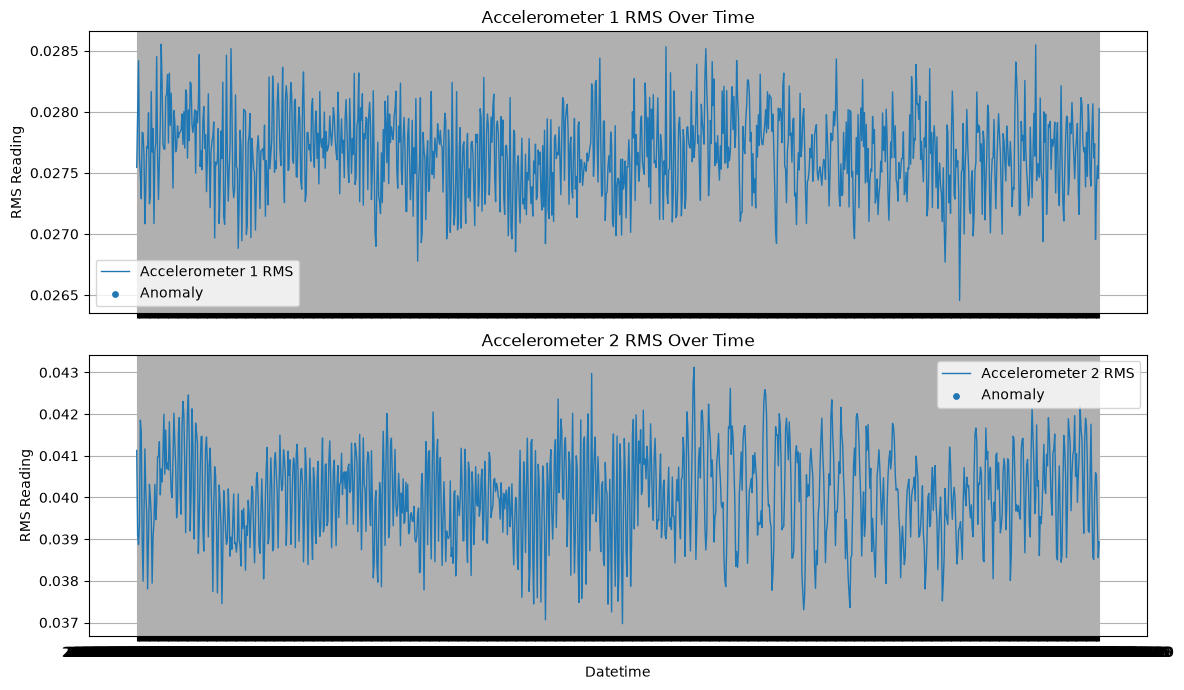

In [6]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Accelerometer 1
axes[0].plot(
    df["datetime"],
    df["Accelerometer1RMS"],
    label="Accelerometer 1 RMS",
    linewidth=1
)

anomalies = df["anomaly"] == 1

axes[0].scatter(
    df.loc[anomalies, "datetime"],
    df.loc[anomalies, "Accelerometer1RMS"],
    label="Anomaly",
    s=15
)

axes[0].set_title("Accelerometer 1 RMS Over Time")
axes[0].set_ylabel("RMS Reading")
axes[0].legend()
axes[0].grid(True)

# Accelerometer 2
axes[1].plot(
    df["datetime"],
    df["Accelerometer2RMS"],
    label="Accelerometer 2 RMS",
    linewidth=1
)

axes[1].scatter(
    df.loc[anomalies, "datetime"],
    df.loc[anomalies, "Accelerometer2RMS"],
    label="Anomaly",
    s=15
)

axes[1].set_title("Accelerometer 2 RMS Over Time")
axes[1].set_xlabel("Datetime")
axes[1].set_ylabel("RMS Reading")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


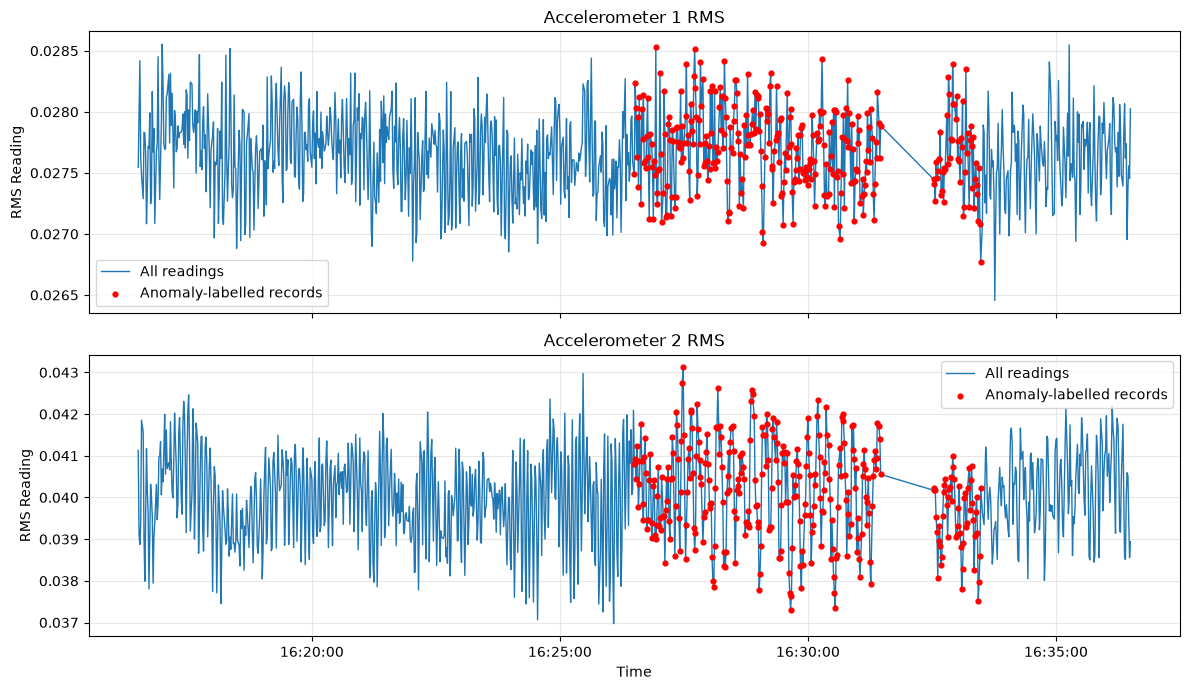

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Convert timestamps if not already converted
df["datetime"] = pd.to_datetime(df["datetime"])

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

sensor_columns = [
    ("Accelerometer1RMS", "Accelerometer 1 RMS"),
    ("Accelerometer2RMS", "Accelerometer 2 RMS")
]

anomalies = df["anomaly"] == 1

for ax, (column, title) in zip(axes, sensor_columns):
    ax.plot(
        df["datetime"], df[column],
        linewidth=1, label="All readings"
    )

    ax.scatter(
        df.loc[anomalies, "datetime"],
        df.loc[anomalies, column],
        color="red", s=12,
        label="Anomaly-labelled records",
        zorder=3
    )

    ax.set_title(title)
    ax.set_ylabel("RMS Reading")
    ax.legend()
    ax.grid(True, alpha=0.3)

# Display a manageable number of date labels
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=6))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
axes[-1].set_xlabel("Time")

plt.tight_layout()
plt.show()



In [2]:
import pandas as pd
from pathlib import Path

file_path = Path("data/raw/1.csv")

# Load the raw dataset
df = pd.read_csv(file_path, sep=";")

# Display dataset information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

FileNotFoundError: [Errno 2] No such file or directory: 'data\\raw\\1.csv'

In [3]:
import pandas as pd
from pathlib import Path

file_path = Path("../data/raw/1.csv")

print("File exists:", file_path.exists())

if file_path.exists():
    df = pd.read_csv(file_path, sep=";")
    print("Dataset shape:", df.shape)
    display(df.head())

File exists: True
Dataset shape: (1063, 11)


,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint
0,2020-03-09 16:16:30,0.027545,0.041127,0.673506,0.054711,67.8345,24.3164,240.513,32.0,0.0,0.0
1,2020-03-09 16:16:31,0.027997,0.039100,0.772264,0.054711,67.8704,24.3279,229.523,32.0,0.0,0.0
2,2020-03-09 16:16:32,0.028418,0.038872,0.675520,0.054711,67.7882,24.3261,242.708,32.0,0.0,0.0
3,2020-03-09 16:16:33,0.027625,0.039366,0.566279,-0.273216,67.7918,24.3323,229.709,32.0,0.0,0.0
4,2020-03-09 16:16:34,0.027484,0.041854,1.292170,0.054711,67.7368,24.3250,242.746,32.0,0.0,0.0


In [4]:
# Step 3: Check timestamp intervals

df["datetime"] = pd.to_datetime(df["datetime"])

# Calculate the time difference between consecutive rows
df["time_interval"] = df["datetime"].diff().dt.total_seconds()

print("Time interval counts:")
print(df["time_interval"].value_counts().sort_index())

print("\nMinimum time interval:",
      df["time_interval"].dropna().min(), "seconds")

print("Maximum time interval:",
      df["time_interval"].dropna().max(), "seconds")

print("\nFirst 10 time intervals:")
display(df[["datetime", "time_interval"]].head(10))

Time interval counts:
time_interval
1.0     986
2.0      75
64.0      1
Name: count, dtype: int64

Minimum time interval: 1.0 seconds
Maximum time interval: 64.0 seconds

First 10 time intervals:


,datetime,time_interval
0,2020-03-09 16:16:30,NaN
1,2020-03-09 16:16:31,1.0
2,2020-03-09 16:16:32,1.0
3,2020-03-09 16:16:33,1.0
4,2020-03-09 16:16:34,1.0
5,2020-03-09 16:16:36,2.0
6,2020-03-09 16:16:37,1.0
7,2020-03-09 16:16:38,1.0
8,2020-03-09 16:16:39,1.0
9,2020-03-09 16:16:40,1.0


In [5]:
# Step 4: Identify missing time intervals

gaps = df[df["time_interval"] > 1][
    ["datetime", "time_interval"]
]

print("Number of gaps:", len(gaps))
print("\nLocations of gaps:")
display(gaps)

print("\nSensor readings around the gaps:")

for index in gaps.index:
    print(f"\nGap at row {index}:")
    display(
        df.loc[
            max(0, index - 1):min(len(df) - 1, index + 1),
            ["datetime", "Accelerometer1RMS",
             "Accelerometer2RMS", "anomaly",
             "time_interval"]
        ]
    )

Number of gaps: 76

Locations of gaps:


,datetime,time_interval
5,2020-03-09 16:16:36,2.0
20,2020-03-09 16:16:52,2.0
34,2020-03-09 16:17:07,2.0
48,2020-03-09 16:17:22,2.0
60,2020-03-09 16:17:35,2.0
...,...,...
987,2020-03-09 16:35:11,2.0
1001,2020-03-09 16:35:26,2.0
1019,2020-03-09 16:35:45,2.0
1037,2020-03-09 16:36:04,2.0



Sensor readings around the gaps:

Gap at row 5:


,datetime,Accelerometer1RMS,Accelerometer2RMS,anomaly,time_interval
4,2020-03-09 16:16:34,0.027484,0.041854,0.0,1.0
5,2020-03-09 16:16:36,0.027288,0.041571,0.0,2.0
6,2020-03-09 16:16:37,0.027832,0.039037,0.0,1.0



Gap at row 20:


,datetime,Accelerometer1RMS,Accelerometer2RMS,anomaly,time_interval
19,2020-03-09 16:16:50,0.027085,0.039404,0.0,1.0
20,2020-03-09 16:16:52,0.027674,0.040315,0.0,2.0
21,2020-03-09 16:16:53,0.027747,0.039466,0.0,1.0


... (144 outputs left out)


Gap at row 1037:


,datetime,Accelerometer1RMS,Accelerometer2RMS,anomaly,time_interval
1036,2020-03-09 16:36:02,0.027677,0.040507,0.0,1.0
1037,2020-03-09 16:36:04,0.027777,0.041053,0.0,2.0
1038,2020-03-09 16:36:05,0.027905,0.039881,0.0,1.0



Gap at row 1053:


,datetime,Accelerometer1RMS,Accelerometer2RMS,anomaly,time_interval
1052,2020-03-09 16:36:19,0.027483,0.040408,0.0,1.0
1053,2020-03-09 16:36:21,0.027392,0.041756,0.0,2.0
1054,2020-03-09 16:36:22,0.027822,0.040001,0.0,1.0


In [7]:
# Step 5: Summarize time gaps

gap_summary = (
    df.loc[df["time_interval"] > 1, "time_interval"]
    .value_counts()
    .sort_index()
)

print("Time Gap Summary:")
print(gap_summary)

print("\nGaps greater than 2 seconds:")

large_gaps = df.loc[
    df["time_interval"] > 2,
    ["datetime", "time_interval"]
]

display(large_gaps)

print("\nTotal records:", len(df))
print("Total gaps greater than 1 second:",
      (df["time_interval"] > 1).sum())

Time Gap Summary:
time_interval
2.0     75
64.0     1
Name: count, dtype: int64

Gaps greater than 2 seconds:


,datetime,time_interval
838,2020-03-09 16:32:32,64.0



Total records: 1063
Total gaps greater than 1 second: 76


In [8]:
# Step 6: Inspect sensor columns

print("Dataset columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary of accelerometer readings:")
display(
    df[["Accelerometer1RMS", "Accelerometer2RMS"]]
    .describe()
)

Dataset columns:
['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint', 'time_interval']

Data types:
datetime               datetime64[us]
Accelerometer1RMS             float64
Accelerometer2RMS             float64
Current                       float64
Pressure                      float64
Temperature                   float64
Thermocouple                  float64
Voltage                       float64
Volume Flow RateRMS           float64
anomaly                       float64
changepoint                   float64
time_interval                 float64
dtype: object

Missing values:
datetime               0
Accelerometer1RMS      0
Accelerometer2RMS      0
Current                0
Pressure               0
Temperature            0
Thermocouple           0
Voltage                0
Volume Flow RateRMS    0
anomaly                0
changepoint            0
time_interval         

,Accelerometer1RMS,Accelerometer2RMS
count,1063.000000,1063.000000
mean,0.027663,0.040037
std,0.000333,0.001086
min,0.026455,0.036972
25%,0.027434,0.039276
50%,0.027674,0.040098
75%,0.027892,0.040828
max,0.028554,0.043122


In [9]:
# Step 7: Detailed data quality check

print("Missing values in each column:")
print(df.isnull().sum().to_string())

print("\nTotal missing values:",
      df.isnull().sum().sum())

print("\nAccelerometer RMS statistics:")
print(
    df[["Accelerometer1RMS", "Accelerometer2RMS"]]
    .describe()
    .to_string()
)

print("\nDuplicate rows:", df.duplicated().sum())

Missing values in each column:
datetime               0
Accelerometer1RMS      0
Accelerometer2RMS      0
Current                0
Pressure               0
Temperature            0
Thermocouple           0
Voltage                0
Volume Flow RateRMS    0
anomaly                0
changepoint            0
time_interval          1

Total missing values: 1

Accelerometer RMS statistics:
       Accelerometer1RMS  Accelerometer2RMS
count        1063.000000        1063.000000
mean            0.027663           0.040037
std             0.000333           0.001086
min             0.026455           0.036972
25%             0.027434           0.039276
50%             0.027674           0.040098
75%             0.027892           0.040828
max             0.028554           0.043122

Duplicate rows: 0


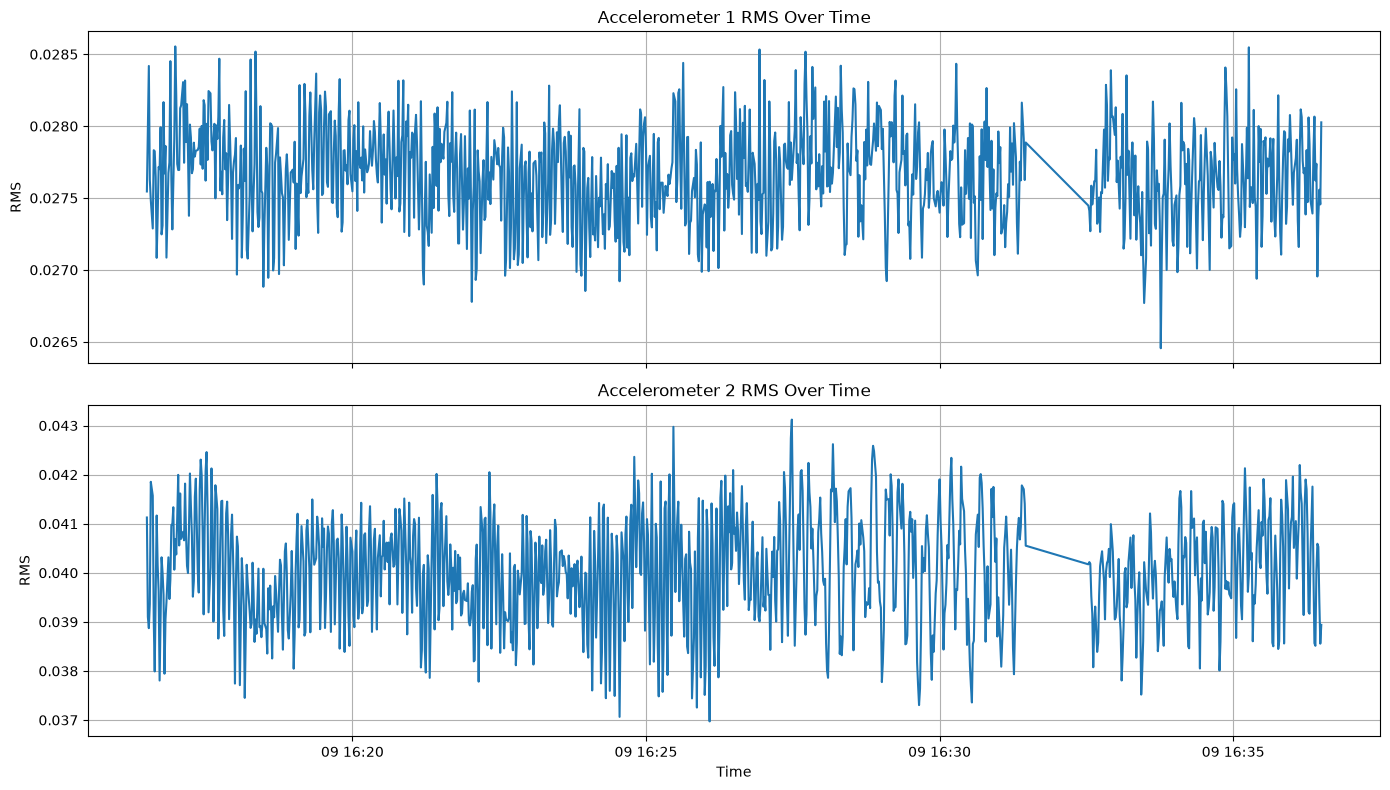

In [10]:
import matplotlib.pyplot as plt

# Step 8: Plot accelerometer RMS readings

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(
    df["datetime"],
    df["Accelerometer1RMS"]
)
axes[0].set_title("Accelerometer 1 RMS Over Time")
axes[0].set_ylabel("RMS")
axes[0].grid(True)

axes[1].plot(
    df["datetime"],
    df["Accelerometer2RMS"]
)
axes[1].set_title("Accelerometer 2 RMS Over Time")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("RMS")
axes[1].grid(True)

plt.tight_layout()
plt.show()

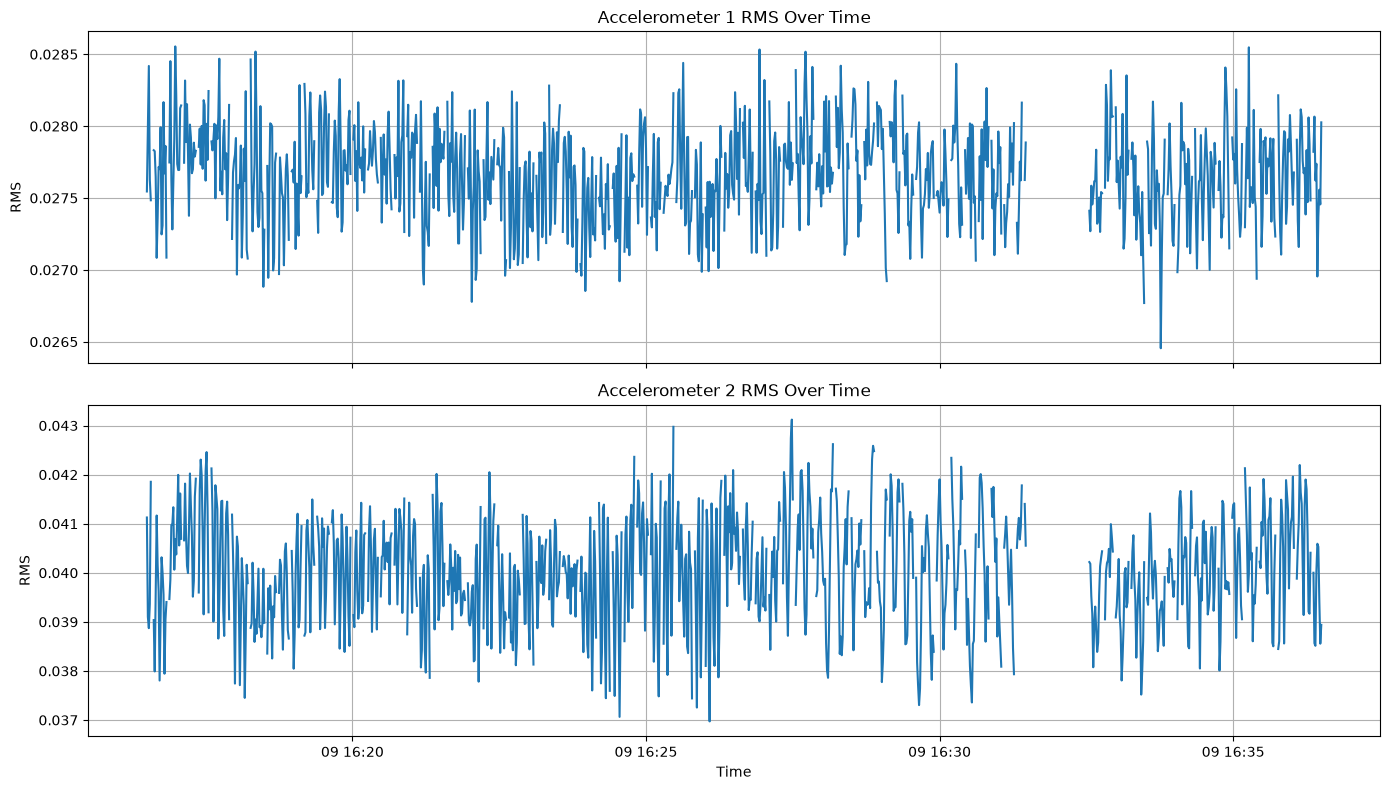

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

# Make sure timestamps are in datetime format
df["datetime"] = pd.to_datetime(df["datetime"])

# Calculate the time difference
time_diff = df["datetime"].diff().dt.total_seconds()

# Break the line at gaps greater than 1 second
acc1 = df["Accelerometer1RMS"].copy()
acc2 = df["Accelerometer2RMS"].copy()

acc1.loc[time_diff > 1] = float("nan")
acc2.loc[time_diff > 1] = float("nan")

# Plot corrected graphs
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(df["datetime"], acc1)
axes[0].set_title("Accelerometer 1 RMS Over Time")
axes[0].set_ylabel("RMS")
axes[0].grid(True)

axes[1].plot(df["datetime"], acc2)
axes[1].set_title("Accelerometer 2 RMS Over Time")
axes[1].set_ylabel("RMS")
axes[1].set_xlabel("Time")
axes[1].grid(True)

plt.tight_layout()
plt.show()

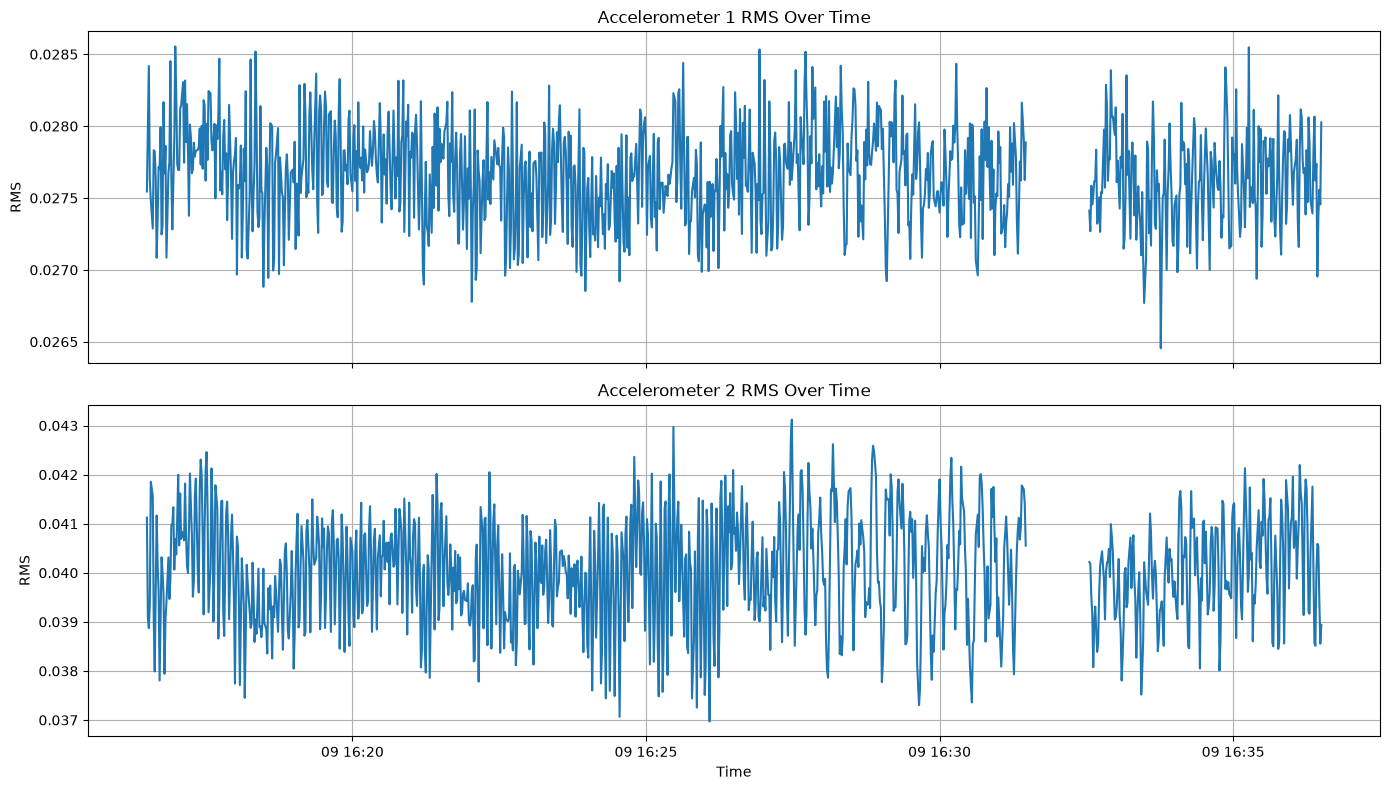

In [12]:
import matplotlib.pyplot as plt

# Calculate the time difference
time_diff = df["datetime"].diff().dt.total_seconds()

# Break lines only at gaps greater than 2 seconds
acc1 = df["Accelerometer1RMS"].copy()
acc2 = df["Accelerometer2RMS"].copy()

acc1.loc[time_diff > 2] = float("nan")
acc2.loc[time_diff > 2] = float("nan")

# Plot the sensor readings
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(df["datetime"], acc1)
axes[0].set_title("Accelerometer 1 RMS Over Time")
axes[0].set_ylabel("RMS")
axes[0].grid(True)

axes[1].plot(df["datetime"], acc2)
axes[1].set_title("Accelerometer 2 RMS Over Time")
axes[1].set_ylabel("RMS")
axes[1].set_xlabel("Time")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [1]:

from pathlib import Path
import pandas as pd

# Find the raw dataset
file_path = Path("data/raw/1.csv")

if not file_path.exists():
    file_path = Path("../data/raw/1.csv")

# Load the CSV using the semicolon separator
df = pd.read_csv(file_path, sep=";")

# Convert datetime column into datetime format
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape (rows, columns):", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


ImportError: DLL load failed while importing mtrand: An Application Control policy has blocked this file.

In [2]:

import csv
from pathlib import Path
from datetime import datetime
from collections import Counter

# Locate the dataset from either the project root or notebooks folder
candidates = [
    Path("data/raw/1.csv"),
    Path("../data/raw/1.csv")
]

file_path = next((p for p in candidates if p.exists()), None)

if file_path is None:
    raise FileNotFoundError("Could not find data/raw/1.csv")

# Read the semicolon-separated CSV
with file_path.open("r", encoding="utf-8-sig", newline="") as file:
    reader = csv.DictReader(file, delimiter=";")
    columns = reader.fieldnames
    rows = list(reader)

print("Dataset loaded successfully!")
print("File:", file_path.resolve())
print("Number of rows:", len(rows))
print("Number of columns:", len(columns))
print("\nColumns:", columns)

print("\nFirst 5 rows:")
for row in rows[:5]:
    print(row)

# Check missing values
print("\nMissing values per column:")
for column in columns:
    missing = sum(
        1 for row in rows
        if row.get(column) is None or not row[column].strip()
    )
    print(f"{column}: {missing}")

# Check duplicate records
print("\nDuplicate rows:", len(rows) - len({
    tuple(row.get(c, "") for c in columns) for row in rows
}))

# Inspect timestamp intervals
timestamps = []
for row in rows:
    try:
        timestamps.append(
            datetime.strptime(row["datetime"], "%Y-%m-%d %H:%M:%S")
        )
    except (ValueError, TypeError, KeyError):
        pass

timestamps.sort()
intervals = [
    int((timestamps[i] - timestamps[i - 1]).total_seconds())
    for i in range(1, len(timestamps))
]

print("\nValid timestamps:", len(timestamps))
print("Time interval counts (seconds):", dict(sorted(Counter(intervals).items())))
if intervals:
    print("Largest time gap (seconds):", max(intervals))


Dataset loaded successfully!
File: C:\Users\Sowmya\OneDrive\Desktop\soumya\Sensor-Telemetry-Anomaly-detection-\data\raw\1.csv
Number of rows: 1063
Number of columns: 11

Columns: ['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

First 5 rows:
{'datetime': '2020-03-09 16:16:30', 'Accelerometer1RMS': '0.0275454', 'Accelerometer2RMS': '0.0411269', 'Current': '0.673506', 'Pressure': '0.054711', 'Temperature': '67.8345', 'Thermocouple': '24.3164', 'Voltage': '240.513', 'Volume Flow RateRMS': '32.0', 'anomaly': '0.0', 'changepoint': '0.0'}
{'datetime': '2020-03-09 16:16:31', 'Accelerometer1RMS': '0.027996899999999998', 'Accelerometer2RMS': '0.0391004', 'Current': '0.7722640000000001', 'Pressure': '0.054711', 'Temperature': '67.8704', 'Thermocouple': '24.3279', 'Voltage': '229.523', 'Volume Flow RateRMS': '32.0', 'anomaly': '0.0', 'changepoint': '0.0'}
{'datetime': '2020-03-

In [3]:

import csv
import statistics
from collections import Counter
from datetime import datetime
from pathlib import Path

file_path = Path("data/raw/1.csv")
if not file_path.exists():
    file_path = Path("../data/raw/1.csv")

with file_path.open("r", encoding="utf-8-sig", newline="") as f:
    rows = list(csv.DictReader(f, delimiter=";"))

# 1. Summary statistics for sensor measurements
sensor_columns = [
    "Accelerometer1RMS",
    "Accelerometer2RMS",
    "Current",
    "Pressure",
    "Temperature",
    "Thermocouple",
    "Voltage",
    "Volume Flow RateRMS"
]

print("SENSOR VALUE SUMMARY")
for column in sensor_columns:
    values = [float(row[column]) for row in rows if row[column].strip()]
    print(f"\n{column}")
    print("  Minimum:", round(min(values), 5))
    print("  Maximum:", round(max(values), 5))
    print("  Mean:", round(statistics.mean(values), 5))
    print("  Median:", round(statistics.median(values), 5))

# 2. Count anomaly and change-point labels
print("\nLABEL COUNTS")
for column in ["anomaly", "changepoint"]:
    counts = Counter(row[column].strip() for row in rows)
    print(column, dict(counts))

# 3. Find large timestamp gaps
timestamps = [
    datetime.strptime(row["datetime"], "%Y-%m-%d %H:%M:%S")
    for row in rows
]

print("\nTIME GAPS GREATER THAN 2 SECONDS")
for i in range(1, len(timestamps)):
    gap = (timestamps[i] - timestamps[i - 1]).total_seconds()
    if gap > 2:
        print(
            timestamps[i - 1], "to", timestamps[i],
            "| Gap:", int(gap), "seconds"
        )


SENSOR VALUE SUMMARY

Accelerometer1RMS
  Minimum: 0.02646
  Maximum: 0.02855
  Mean: 0.02766
  Median: 0.02767

Accelerometer2RMS
  Minimum: 0.03697
  Maximum: 0.04312
  Mean: 0.04004
  Median: 0.0401

Current
  Minimum: 0.39406
  Maximum: 232.734
  Mean: 1.19524
  Median: 1.00272

Pressure
  Minimum: -0.92907
  Maximum: 1.03849
  Mean: 0.04854
  Median: 0.05471

Temperature
  Minimum: 66.2019
  Maximum: 69.0982
  Mean: 67.89517
  Median: 67.955

Thermocouple
  Minimum: 24.217
  Maximum: 24.3323
  Mean: 24.2651
  Median: 24.2672

Voltage
  Minimum: 0.58078
  Maximum: 254.125
  Mean: 229.92482
  Median: 230.634

Volume Flow RateRMS
  Minimum: 28.04
  Maximum: 33.0
  Mean: 31.47227
  Median: 32.0

LABEL COUNTS
anomaly {'0.0': 730, '1.0': 333}
changepoint {'0.0': 1059, '1.0': 4}

TIME GAPS GREATER THAN 2 SECONDS
2020-03-09 16:31:28 to 2020-03-09 16:32:32 | Gap: 64 seconds


In [4]:

import csv
from pathlib import Path

file_path = Path("data/raw/1.csv")
if not file_path.exists():
    file_path = Path("../data/raw/1.csv")

with file_path.open("r", encoding="utf-8-sig", newline="") as f:
    rows = list(csv.DictReader(f, delimiter=";"))

for label in ["anomaly", "changepoint"]:
    flagged = [
        row for row in rows
        if float(row[label]) == 1.0
    ]

    print(f"\n{label.upper()}")
    print("Flagged records:", len(flagged))
    print("Label counts:")
    print({
        "0.0": sum(float(row[label]) == 0.0 for row in rows),
        "1.0": len(flagged)
    })

    for row in flagged:
        print(row["datetime"], "|", label, "=", row[label])



ANOMALY
Flagged records: 333
Label counts:
{'0.0': 730, '1.0': 333}
2020-03-09 16:26:30 | anomaly = 1.0
2020-03-09 16:26:31 | anomaly = 1.0
2020-03-09 16:26:32 | anomaly = 1.0
2020-03-09 16:26:33 | anomaly = 1.0
2020-03-09 16:26:34 | anomaly = 1.0
2020-03-09 16:26:35 | anomaly = 1.0
2020-03-09 16:26:36 | anomaly = 1.0
2020-03-09 16:26:38 | anomaly = 1.0
2020-03-09 16:26:39 | anomaly = 1.0
2020-03-09 16:26:40 | anomaly = 1.0
2020-03-09 16:26:41 | anomaly = 1.0
2020-03-09 16:26:42 | anomaly = 1.0
2020-03-09 16:26:43 | anomaly = 1.0
2020-03-09 16:26:44 | anomaly = 1.0
2020-03-09 16:26:45 | anomaly = 1.0
2020-03-09 16:26:46 | anomaly = 1.0
2020-03-09 16:26:47 | anomaly = 1.0
2020-03-09 16:26:48 | anomaly = 1.0
2020-03-09 16:26:49 | anomaly = 1.0
2020-03-09 16:26:51 | anomaly = 1.0
2020-03-09 16:26:52 | anomaly = 1.0
2020-03-09 16:26:53 | anomaly = 1.0
2020-03-09 16:26:54 | anomaly = 1.0
2020-03-09 16:26:55 | anomaly = 1.0
2020-03-09 16:26:56 | anomaly = 1.0
2020-03-09 16:26:57 | anomaly =

In [5]:

import csv
from pathlib import Path

file_path = Path("data/raw/1.csv")

if not file_path.exists():
    file_path = Path("../data/raw/1.csv")

with file_path.open("r", encoding="utf-8-sig", newline="") as f:
    rows = list(csv.DictReader(f, delimiter=";"))

# Find the record with the highest current reading
max_index = max(
    range(len(rows)),
    key=lambda i: float(rows[i]["Current"])
)

print("Highest current reading:")
print(rows[max_index])

# Display three records before and after it
print("\nNearby sensor readings:")

start = max(0, max_index - 3)
end = min(len(rows), max_index + 4)

for i in range(start, end):
    row = rows[i]
    print(
        row["datetime"],
        "| Current:", row["Current"],
        "| Accelerometer1RMS:", row["Accelerometer1RMS"],
        "| Accelerometer2RMS:", row["Accelerometer2RMS"],
        "| Anomaly:", row["anomaly"],
        "| Changepoint:", row["changepoint"]
    )

# Compare normal and anomalous current readings
print("\nCurrent comparison:")

for label in ["0.0", "1.0"]:
    values = [
        float(row["Current"])
        for row in rows
        if row["anomaly"] == label
    ]

    if values:
        print(
            "Anomaly =", label,
            "| Count =", len(values),
            "| Mean current =", round(sum(values) / len(values), 5),
            "| Maximum current =", round(max(values), 5)
        )


Highest current reading:
{'datetime': '2020-03-09 16:35:27', 'Accelerometer1RMS': '0.0277504', 'Accelerometer2RMS': '0.0402256', 'Current': '232.734', 'Pressure': '0.38263800000000003', 'Temperature': '67.3543', 'Thermocouple': '24.2247', 'Voltage': '0.5807760000000001', 'Volume Flow RateRMS': '31.0407', 'anomaly': '0.0', 'changepoint': '0.0'}

Nearby sensor readings:
2020-03-09 16:35:23 | Current: 0.595224 | Accelerometer1RMS: 0.027438900000000002 | Accelerometer2RMS: 0.039755900000000004 | Anomaly: 0.0 | Changepoint: 0.0
2020-03-09 16:35:24 | Current: 0.791495 | Accelerometer1RMS: 0.0269384 | Accelerometer2RMS: 0.040510199999999996 | Anomaly: 0.0 | Changepoint: 0.0
2020-03-09 16:35:26 | Current: 0.994151 | Accelerometer1RMS: 0.027999999999999997 | Accelerometer2RMS: 0.041276099999999996 | Anomaly: 0.0 | Changepoint: 0.0
2020-03-09 16:35:27 | Current: 232.734 | Accelerometer1RMS: 0.0277504 | Accelerometer2RMS: 0.0402256 | Anomaly: 0.0 | Changepoint: 0.0
2020-03-09 16:35:28 | Current: 

In [6]:
import pandas as pd

# Load the sensor dataset
df = pd.read_csv("data/raw/sensor_data.csv")

# Convert Current column to numeric
df["Current"] = pd.to_numeric(df["Current"], errors="coerce")

# Display the 10 highest current readings
highest_current = df.nlargest(10, "Current")

print(highest_current[
    ["datetime", "Current", "anomaly", "changepoint"]
])

ImportError: DLL load failed while importing mtrand: An Application Control policy has blocked this file.

In [7]:

# Task 3: Detect unusual current readings

import math

def is_number(value):
    try:
        return math.isfinite(float(value))
    except (ValueError, TypeError):
        return False

# Get valid current readings
current_values = [
    float(row["Current"])
    for row in rows
    if is_number(row.get("Current", ""))
]

if not current_values:
    print("No valid current readings found.")
else:
    # Calculate quartiles
    current_values.sort()
    n = len(current_values)

    q1 = current_values[int(n * 0.25)]
    q3 = current_values[int(n * 0.75)]

    # Calculate IQR limits
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    print("Q1:", round(q1, 5))
    print("Q3:", round(q3, 5))
    print("IQR:", round(iqr, 5))
    print("Lower limit:", round(lower_limit, 5))
    print("Upper limit:", round(upper_limit, 5))

    # Identify possible outliers
    outliers = [
        row for row in rows
        if is_number(row.get("Current", ""))
        and (
            float(row["Current"]) < lower_limit
            or float(row["Current"]) > upper_limit
        )
    ]

    print("\nTotal possible outliers:", len(outliers))

    for row in outliers[:10]:
        print(
            row["datetime"],
            "| Current:", row["Current"],
            "| Anomaly:", row["anomaly"]
        )


Q1: 0.75323
Q3: 1.19497
IQR: 0.44174
Lower limit: 0.09062
Upper limit: 1.85758

Total possible outliers: 1
2020-03-09 16:35:27 | Current: 232.734 | Anomaly: 0.0


In [8]:

# Task 4: Compare current and accelerometer readings

print("Sensor readings around the current spike:\n")

for i in range(max(0, max_index - 5),
               min(len(rows), max_index + 6)):

    row = rows[i]

    print(
        row["datetime"],
        "| Current:", row["Current"],
        "| Acc1 RMS:", row["Accelerometer1RMS"],
        "| Acc2 RMS:", row["Accelerometer2RMS"]
    )


Sensor readings around the current spike:

2020-03-09 16:35:21 | Current: 1.1728399999999999 | Acc1 RMS: 0.0281127 | Acc2 RMS: 0.0395406
2020-03-09 16:35:22 | Current: 0.415865 | Acc1 RMS: 0.027504 | Acc2 RMS: 0.039370999999999996
2020-03-09 16:35:23 | Current: 0.595224 | Acc1 RMS: 0.027438900000000002 | Acc2 RMS: 0.039755900000000004
2020-03-09 16:35:24 | Current: 0.791495 | Acc1 RMS: 0.0269384 | Acc2 RMS: 0.040510199999999996
2020-03-09 16:35:26 | Current: 0.994151 | Acc1 RMS: 0.027999999999999997 | Acc2 RMS: 0.041276099999999996
2020-03-09 16:35:27 | Current: 232.734 | Acc1 RMS: 0.0277504 | Acc2 RMS: 0.0402256
2020-03-09 16:35:28 | Current: 0.731046 | Acc1 RMS: 0.0279807 | Acc2 RMS: 0.040096
2020-03-09 16:35:29 | Current: 0.45950699999999994 | Acc1 RMS: 0.027160300000000002 | Acc2 RMS: 0.0410352
2020-03-09 16:35:30 | Current: 0.497475 | Acc1 RMS: 0.027374799999999998 | Acc2 RMS: 0.0407582
2020-03-09 16:35:31 | Current: 0.835224 | Acc1 RMS: 0.027896299999999995 | Acc2 RMS: 0.0419108


In [9]:

# Task 5: Detect vibration outliers using the IQR method

def find_outliers(column):
    values = sorted(
        float(row[column])
        for row in rows
        if is_number(row.get(column, ""))
    )

    n = len(values)
    if n < 4:
        print(column, ": Not enough valid readings")
        return

    q1 = values[int(n * 0.25)]
    q3 = values[int(n * 0.75)]
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = [
        row for row in rows
        if is_number(row.get(column, ""))
        and (
            float(row[column]) < lower
            or float(row[column]) > upper
        )
    ]

    print("\nSensor:", column)
    print("Lower limit:", round(lower, 6))
    print("Upper limit:", round(upper, 6))
    print("Number of outliers:", len(outliers))

    for row in outliers[:5]:
        print(
            row["datetime"],
            "| Value:", row[column],
            "| Anomaly:", row["anomaly"]
        )


find_outliers("Accelerometer1RMS")
find_outliers("Accelerometer2RMS")



Sensor: Accelerometer1RMS
Lower limit: 0.026745
Upper limit: 0.028581
Number of outliers: 1
2020-03-09 16:33:46 | Value: 0.026455000000000003 | Anomaly: 0.0

Sensor: Accelerometer2RMS
Lower limit: 0.036938
Upper limit: 0.043164
Number of outliers: 0


In [10]:
# Task 6: Compare vibration readings by anomaly label

for column in ["Accelerometer1RMS", "Accelerometer2RMS"]:
    print("\nSensor:", column)

    for label in ["0.0", "1.0"]:
        values = [
            float(row[column])
            for row in rows
            if row.get("anomaly") == label
            and is_number(row.get(column, ""))
        ]

        if values:
            print(
                "Anomaly =", label,
                "| Count =", len(values),
                "| Mean =", round(sum(values) / len(values), 6),
                "| Maximum =", round(max(values), 6)
            )


Sensor: Accelerometer1RMS
Anomaly = 0.0 | Count = 730 | Mean = 0.02765 | Maximum = 0.028554
Anomaly = 1.0 | Count = 333 | Mean = 0.027692 | Maximum = 0.028533

Sensor: Accelerometer2RMS
Anomaly = 0.0 | Count = 730 | Mean = 0.040007 | Maximum = 0.042974
Anomaly = 1.0 | Count = 333 | Mean = 0.040102 | Maximum = 0.043122


In [11]:
# Task 7: Calculate vibration difference between normal and anomalous readings

for column in ["Accelerometer1RMS", "Accelerometer2RMS"]:
    print("\nSensor:", column)

    normal_values = [
        float(row[column])
        for row in rows
        if row.get("anomaly") == "0.0"
        and is_number(row.get(column, ""))
    ]

    anomaly_values = [
        float(row[column])
        for row in rows
        if row.get("anomaly") == "1.0"
        and is_number(row.get(column, ""))
    ]

    if normal_values and anomaly_values:
        normal_mean = sum(normal_values) / len(normal_values)
        anomaly_mean = sum(anomaly_values) / len(anomaly_values)

        print("Normal Mean:", round(normal_mean, 6))
        print("Anomaly Mean:", round(anomaly_mean, 6))
        print(
            "Mean Difference:",
            round(anomaly_mean - normal_mean, 6)
        )

        if anomaly_mean > normal_mean:
            print("Result: Vibration is higher during anomalies.")
        elif anomaly_mean < normal_mean:
            print("Result: Vibration is lower during anomalies.")
        else:
            print("Result: Both mean vibration values are equal.")


Sensor: Accelerometer1RMS
Normal Mean: 0.02765
Anomaly Mean: 0.027692
Mean Difference: 4.2e-05
Result: Vibration is higher during anomalies.

Sensor: Accelerometer2RMS
Normal Mean: 0.040007
Anomaly Mean: 0.040102
Mean Difference: 9.5e-05
Result: Vibration is higher during anomalies.


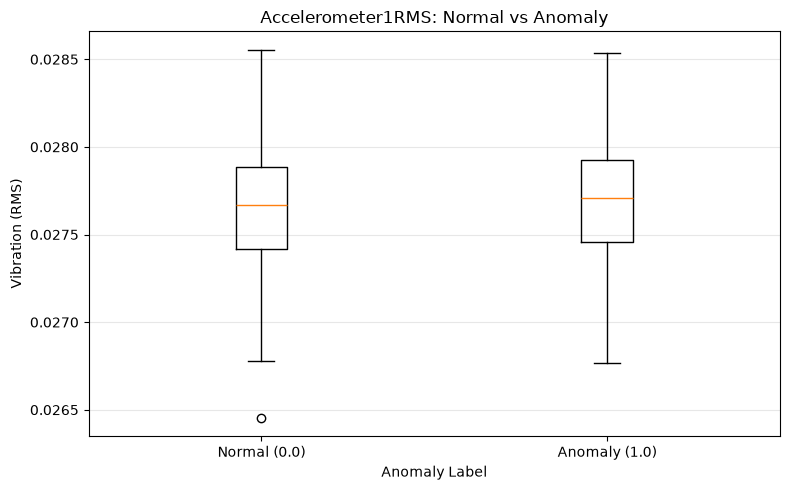

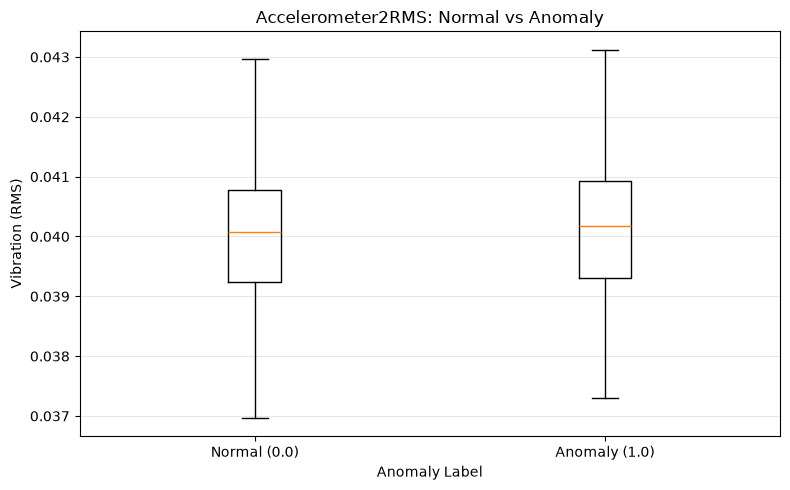

In [12]:
# Task 8: Visualize vibration readings by anomaly label

import matplotlib.pyplot as plt

for column in ["Accelerometer1RMS", "Accelerometer2RMS"]:
    normal_values = [
        float(row[column])
        for row in rows
        if row.get("anomaly") == "0.0"
        and is_number(row.get(column, ""))
    ]

    anomaly_values = [
        float(row[column])
        for row in rows
        if row.get("anomaly") == "1.0"
        and is_number(row.get(column, ""))
    ]

    plt.figure(figsize=(8, 5))

    plt.boxplot(
        [normal_values, anomaly_values],
        tick_labels=["Normal (0.0)", "Anomaly (1.0)"]
    )

    plt.title(f"{column}: Normal vs Anomaly")
    plt.xlabel("Anomaly Label")
    plt.ylabel("Vibration (RMS)")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()